<a href="https://colab.research.google.com/github/Luoxiaowanzi/Class/blob/main/Copy_of_lab_09_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> ### Note on Labs and Assignments:
>
> 🔧 Look for the **wrench emoji** 🔧 — it highlights where you're expected to take action!
>
> These sections are graded and are not optional.
>

# **IS 4487 LAB 9: CLUSTERING**

In this lab, we return to the **SF Rent** dataset that we used in **Lab 4: Data Understanding** and **Lab 5: Exploratory Data Analysis (EDA)**.

This time, we’ll explore how to segment the counties using both:
- **Manual clustering** based on business rules
- **Automatic clustering** using KMeans clustering

Segmentation helps identify meaningful groups within data, such as counties with high rent burden or low affordability. This is valuable for making targeted decisions in housing policy, urban planning, and social support.


## Outline

- Load and inspect the SF Rents dataset  
- Engineer and prepare features  
- Create manual segments using binning  
- Perform KMeans clustering for automatic segments  
- Visualize and compare results  

<a href="https://colab.research.google.com/github/vandanara/UofUtah_IS4487/blob/main/Labs/lab_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## **Context: Rental Housing Market in the Bay Area**

## Dataset Overview
The data contains posts about Bay Area rental housing on Craigslist.

**Dataset:** `rent.csv`  
Source: [TidyTuesday 2022-07-05](https://github.com/rfordatascience/tidytuesday/blob/main/data/2022/2022-07-05/rent.csv)

| Variable       | Type       | Description |
|----------------|------------|-------------|
| `post_id`      | Categorical| Unique listing ID |
| `date`         | Numeric    | Listing date (numeric format) |
| `year`         | Integer    | Year of listing |
| `nhood`        | Categorical| Neighborhood |
| `city`         | Categorical| City |
| `county`       | Categorical| County |
| `price`        | Numeric    | Listing price (USD) |
| `beds`         | Numeric    | Number of bedrooms |
| `baths`        | Numeric    | Number of bathrooms |
| `sqft`         | Numeric    | Square footage |
| `room_in_apt`  | Binary     | 1 = room in apartment |
| `address`      | Categorical| Street address |
| `lat`          | Numeric    | Latitude |
| `lon`          | Numeric    | Longitude |
| `title`        | Text       | Listing title |
| `descr`        | Text       | Listing description |
| `details`      | Text       | Additional details |


## **Part 1: Importing the Data + Prepare for Segmentation**

### Instructions:
- Import necessary libraries.
- Import data from the rent.csv into a dataframe from the tidytuesday link.
- Use `.info()` and `.head()` to inspect the structure and preview the data.e structure and preview the data.
- Perform basic data cleanup including
  - Remove duplicates
  - Handle missing values (Optionally impute or filter variables)
  - Remove outliers (for price, beds, baths, sqft)
  - Fix data types

Note: we will do a few quick and easy steps for this Lab. Of course, in general, you will want to perform a more thorough cleaning .

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
url = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2022/2022-07-05/rent.csv'
df = pd.read_csv(url)

# Get a quick overview
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200796 entries, 0 to 200795
Data columns (total 17 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   post_id      200796 non-null  object 
 1   date         200796 non-null  int64  
 2   year         200796 non-null  int64  
 3   nhood        200796 non-null  object 
 4   city         200796 non-null  object 
 5   county       199402 non-null  object 
 6   price        200796 non-null  int64  
 7   beds         194188 non-null  float64
 8   baths        42675 non-null   float64
 9   sqft         64679 non-null   float64
 10  room_in_apt  200796 non-null  int64  
 11  address      3908 non-null    object 
 12  lat          7651 non-null    float64
 13  lon          4312 non-null    float64
 14  title        198279 non-null  object 
 15  descr        3254 non-null    object 
 16  details      8016 non-null    object 
dtypes: float64(5), int64(4), object(8)
memory usage: 26.0+ MB
None


In [ ]:
display(df.head())

display(df.describe())

,post_id,date,year,nhood,city,county,price,beds,baths,sqft,room_in_apt,address,lat,lon,title,descr,details
0,pre2013_134138,20050111,2005,alameda,alameda,alameda,1250,2.0,2.0,NaN,0,NaN,NaN,NaN,$1250 / 2br - 2BR/2BA 1145 ALAMEDA DE LAS PU...,NaN,NaN
1,pre2013_135669,20050126,2005,alameda,alameda,alameda,1295,2.0,NaN,NaN,0,NaN,NaN,NaN,$1295 / 2br - Walk the Beach! 1 FREE MONTH + $...,NaN,NaN
2,pre2013_127127,20041017,2004,alameda,alameda,alameda,1100,2.0,NaN,NaN,0,NaN,NaN,NaN,$1100 / 2br - cottage,NaN,NaN
3,pre2013_68671,20120601,2012,alameda,alameda,alameda,1425,1.0,NaN,735.0,0,NaN,NaN,NaN,$1425 / 1br - 735ft² - BEST LOCATION SOUTHSHOR...,NaN,NaN
4,pre2013_127580,20041021,2004,alameda,alameda,alameda,890,1.0,NaN,NaN,0,NaN,NaN,NaN,"$890 / 1br - Classy ""Painted Lady"" VICTORIAN -...",NaN,NaN


,date,year,price,beds,baths,sqft,room_in_apt,lat,lon
count,2.007960e+05,200796.000000,200796.000000,194188.000000,42675.000000,64679.000000,200796.000000,7651.000000,4312.000000
mean,2.009572e+07,2009.507899,2135.362746,1.889025,1.679086,1201.827688,0.001419,37.666060,-122.210272
std,4.469407e+04,4.476676,1427.747903,1.079138,0.690509,5000.217864,0.037648,0.346889,0.776726
min,2.000090e+07,2000.000000,220.000000,0.000000,1.000000,80.000000,0.000000,33.570100,-123.196500
25%,2.005023e+07,2005.000000,1295.000000,1.000000,1.000000,750.000000,0.000000,37.400841,-122.423500
50%,2.011092e+07,2011.000000,1800.000000,2.000000,2.000000,1000.000000,0.000000,37.756512,-122.263314
75%,2.012080e+07,2012.000000,2505.000000,3.000000,2.000000,1360.000000,0.000000,37.797901,-121.996375
max,2.018072e+07,2018.000000,40000.000000,12.000000,8.000000,900000.000000,1.000000,40.434945,-74.198019


In [ ]:
# STEP 1: Drop duplicates with the same post ID
df = df.drop_duplicates(subset='post_id')

# STEP 2: Drop rows with nulls in essential columns - the ones we decide to use for clustering
essential = ['price', 'beds', 'baths', 'sqft', 'lat', 'lon']
df = df.dropna(subset=essential)

# STEP 3: Remove outliers (common-sense filtering)
df = df[df['price'].between(500, 20000)]
df = df[df['beds'].between(0, 10)]
df = df[df['baths'].between(0.5, 10)]
df = df[df['sqft'].between(100, 5000)]

# STEP 4: Convert data types if needed
df['beds'] = df['beds'].astype(int)
df['baths'] = df['baths'].astype(float)  # decimal values allowed
df['sqft'] = df['sqft'].astype(int)
df['price'] = df['price'].astype(int)

# STEP 5: Reset index
# creates an int index of 0,1,2,3...and moves the existing index to a column
# this is helpful if we want the index to actually be one of the columns. ISnce our index is 0,1,2, already, we will just drop it.
df = df.reset_index(drop=True)

# Preview cleaned data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1984 entries, 0 to 1983
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   post_id      1984 non-null   object 
 1   date         1984 non-null   int64  
 2   year         1984 non-null   int64  
 3   nhood        1984 non-null   object 
 4   city         1984 non-null   object 
 5   county       1979 non-null   object 
 6   price        1984 non-null   int64  
 7   beds         1984 non-null   int64  
 8   baths        1984 non-null   float64
 9   sqft         1984 non-null   int64  
 10  room_in_apt  1984 non-null   int64  
 11  address      1768 non-null   object 
 12  lat          1984 non-null   float64
 13  lon          1984 non-null   float64
 14  title        1855 non-null   object 
 15  descr        1847 non-null   object 
 16  details      1874 non-null   object 
dtypes: float64(3), int64(6), object(8)
memory usage: 263.6+ KB


In [ ]:
df.sample(n=5)

,post_id,date,year,nhood,city,county,price,beds,baths,sqft,room_in_apt,address,lat,lon,title,descr,details
1887,4635256739,20140831,2014,USF / anza vista,san francisco,san francisco,6900,4,4.0,1700,0,1633,37.780940,-122.453000,Sleek Modern Spacious Full Floor - 4 Master Su...,756 Spruce StreetBill Harkins Brokerage #01230...,"4BR / 4Ba 1700ft2 apartment date=""2015-08-05""..."
1071,5313254075,20151113,2015,redwood city,redwood city,san mateo,2978,0,1.0,627,0,2367,37.485858,-122.231634,One bedroom on the 6th floor coming soon! $500...,Floor plan: A2 *******LOOK & LEASE TO SAVE $50...,"1BR / 1Ba 627ft2 date=""2015-12-23"" today_msg=..."
1125,5344298097,20151204,2015,russian hill,san francisco,san francisco,3700,1,1.0,900,0,NaN,37.791416,-122.414107,NaN,"CONTACT INFOPamela Kelley, Mba, Breiletşm bil ...","1BR / 1Ba 900ft2 date=""2015-12-15"" today_msg=..."
179,4956722658,20150331,2015,concord / pleasant hill / martinez,concord,contra costa,2522,2,1.0,1112,0,2108,37.977722,-122.036773,Beauty And Luxury Describes This Fantastic Two...,Relax. Breathe. Unwind. Refresh.Welcome Home!C...,"2BR / 2Ba 1112ft2 apartment date=""2015-06-30""..."
1185,5322103621,20151204,2015,san jose central,san jose,santa clara,4000,3,1.5,1300,0,2435,37.351141,-121.901966,NaN,This Storybook home is in the Japantown area o...,"3BR / 1.5Ba 1300ft2 date=""2016-01-01"" today_m..."


While this drops a significant amount of data, we wouldnot have been able to do clustering on those observations since they had missing values. Alternatively, if we had enough information/intuition, we could have imputed some of the missing values to keep more of the rows.

## **Part 2: Engineer and Prepare Features**

We’ll select features for clustering:
- Property: `price`, `beds`, `baths`, `sqft`
- Geographic: `lat`, `lon`

We need to ensure that all these features that we use for clustering are in the same scale. We can either choose standardization (mean = 0, var = 1) or minmax normalization (0-1). We’ll standardize features to ensure fair weighting in distance-based clustering.

### Why This Matters:
Scaling avoids giving larger-scale variables (like `price`) more influence in ML algorithms, such as Clustering, that are based on distance measures. Otherwise we will get clitsre that are heavily influenced by only the larger scale features, ignoring the smaller scaled features, which need not reflect reality.

### Things to think about:
- Should all variables be scaled?
- Do geographic coordinates need scaling?


In [ ]:
from sklearn.preprocessing import StandardScaler

# Select and scale features
features = ['price', 'beds', 'baths', 'sqft', 'lat', 'lon']
segment_df = df[features].copy()

# apply standardization
scaler = StandardScaler()
scaled_data = scaler.fit_transform(segment_df)

# Convert back to DataFrame
scaled_df = pd.DataFrame(scaled_data, columns=features)
scaled_df.describe()


,price,beds,baths,sqft,lat,lon
count,1.984000e+03,1.984000e+03,1.984000e+03,1.984000e+03,1.984000e+03,1.984000e+03
mean,-2.865092e-17,-1.396732e-16,-5.909252e-17,6.804593e-17,1.065814e-14,3.175238e-14
std,1.000252e+00,1.000252e+00,1.000252e+00,1.000252e+00,1.000252e+00,1.000252e+00
min,-1.337208e+00,-1.820352e+00,-7.729405e-01,-1.818334e+00,-2.246088e+00,-4.049695e+00
25%,-6.096674e-01,-9.283842e-01,-7.729405e-01,-6.528168e-01,-8.540262e-01,-9.211282e-01
50%,-2.066991e-01,-3.641604e-02,-7.729405e-01,-2.305528e-01,-1.483437e-01,2.523113e-01
75%,2.693202e-01,8.555521e-01,6.826969e-01,3.964064e-01,4.973067e-01,8.194491e-01
max,9.920366e+00,4.423425e+00,4.321790e+00,6.220132e+00,4.473467e+00,3.716981e+00


### 🔧 **Try It Yourself - Part 2**

2.1. Why should lat/lon (latitude and longitude) be scaled before clustering? What would happen if they weren’t? (There’s no coding here, just write your response below.)


🔧 2.1 Add comment here:

We need to scale latitude and longitude so all variables are on a similar scale. If we don't scale them, variables with larger values, like price, may have more influence on the clusters. This can make the results less accurate.

## **Part 3: Create Manual Segments Using Binning**

Let’s group listings by price into:
  - **Low**: < $2,000

  - **Mid**: \$2,000 - $4,000
  
  - **High**: > $4,000

### Why This Matters:
Manual bins based on thresholds offer simple segmentation — useful when business rules exist.

### Things to think about:
- Why might one want to create such manual bins or segments based on one or few features?
- Are fixed or custom cutoffs (that use `pd.cut()`) better than percentiles/quantiles using `pd.qcut()`?
- Should you also bin square footage?


In [ ]:
# Create price segments
df['price_segment'] = pd.cut(
    df['price'],
    bins=[0, 2000, 4000, float('inf')],
    labels=['Low', 'Mid', 'High']
)

df['price_segment'].value_counts()


,count
price_segment,
Mid,1195
Low,493
High,296


### 🔧 **Try It Yourself - Part 3**

3.1. Create a column called `sqft_segment` using bins:  
  - Small: `< 800`,
  - Medium: `800–1400`,
  - Large: `>1400`  

3.2. Count how many listings fall into each `sqft_segment` using `.value_counts()`  

3.3. Use `.head()` or `.sample()` to preview 5 values of both `price_segment` and `sqft_segment`

In [ ]:
# 🔧 3.1. Add code here
df['sqft_segment'] = pd.cut(
    df['sqft'],
    bins=[0, 799, 1400, float('inf')],
    labels=['Small', 'Medium', 'Large']
)

# 🔧 3.2. Add code here
print("Value counts for sqft_segment:")
display(df['sqft_segment'].value_counts())

# 🔧 3.3. Add code here
print("\nPreview of both price_segment and sqft_segment:")
display(df[['price_segment', 'sqft_segment']].head())


Value counts for sqft_segment:


,count
sqft_segment,
Medium,981
Large,504
Small,499



Preview of both price_segment and sqft_segment:


,price_segment,sqft_segment
0,Low,Medium
1,Mid,Medium
2,Mid,Large
3,Mid,Medium
4,Mid,Medium


## **Part 4: Perform K-Means Clustering**

We’ll create two sets of clusters:
1. **Home feature-based** (price, beds, baths, sqft)
2. **Geographic-based** (lat, lon)

### Why This Matters:
Unsupervised clustering finds hidden patterns — useful for market segmentation, targeting, etc.

### Things to think about:
- How many clusters should you use?
- How do results differ between property and location clusters?


In [ ]:
from sklearn.cluster import KMeans

# Select only the standardized property/home features
X_home = scaled_df[['price', 'beds', 'baths', 'sqft']]

# Apply KMeans clustering with 4 clusters
kmeans_home = KMeans(n_clusters=4, random_state=35)     # set the seed as any random int
scaled_df['homefeature_cluster'] = kmeans_home.fit_predict(X_home)

# Show number of listings in each cluster
scaled_df['homefeature_cluster'].value_counts()


,count
homefeature_cluster,
1,969
3,672
2,305
0,38


In [ ]:
# Select only standardized geographic coordinate features
X_geo = scaled_df[['lat', 'lon']]

# Apply KMeans clustering with 5 clusters
kmeans_geo = KMeans(n_clusters=5, random_state=35)
scaled_df['geo_cluster'] = kmeans_geo.fit_predict(X_geo)

# Show number of listings in each geographic cluster
scaled_df['geo_cluster'].value_counts()

,count
geo_cluster,
1,663
0,622
4,398
3,190
2,111


### 🔧 **Try It Yourself - Part 4**

4.1. Run KMeans again using `k=3` (3 clusters instead of 4) for Cluster based on home_features. Save these clusters as a new column in scaled_df, say, `homefeature_cluster2`. Then compare the value counts of the old K-Means cluster with your new K-Means cluster using `pd.crosstab()`.

4.2. Plot a histogram of `price` grouped by `homefeature_cluster2`. Add appropriate titles, heading ad axis labels.

Comparison of old (k=4) vs new (k=3) clusters:


homefeature_cluster2,0,1,2
homefeature_cluster,,,
0,38,0,0
1,0,969,0
2,107,0,198
3,0,63,609


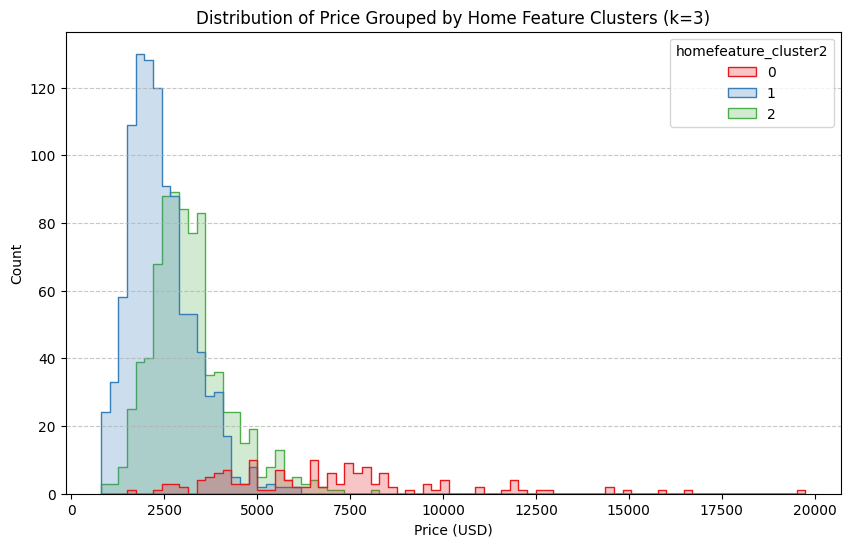

In [ ]:
# 🔧 4.1. Add code here
kmeans_home2 = KMeans(n_clusters=3, random_state=35)
scaled_df['homefeature_cluster2'] = kmeans_home2.fit_predict(X_home)

# Compare the old (k=4) and new (k=3) clusters
print("Comparison of old (k=4) vs new (k=3) clusters:")
display(pd.crosstab(scaled_df['homefeature_cluster'], scaled_df['homefeature_cluster2']))

# 🔧 4.2. Add code here
# Add the new cluster labels back to the original df for unscaled price analysis
df['homefeature_cluster2'] = scaled_df['homefeature_cluster2']

plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='price', hue='homefeature_cluster2', element='step', stat='count', common_norm=False, palette='Set1')
plt.title("Distribution of Price Grouped by Home Feature Clusters (k=3)")
plt.xlabel("Price (USD)")
plt.ylabel("Count")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## **Part 5: Visualize and Compare Results**

We’ll now visualize:
- Clusters on a map (lat/lon)
- Clusters in price vs sqft space

### Why This Matters:
Visual validation helps determine if clusters are interpretable and useful.

### Things to think about:
- Are location clusters geographically meaningful?
- Do property clusters separate by price or size?

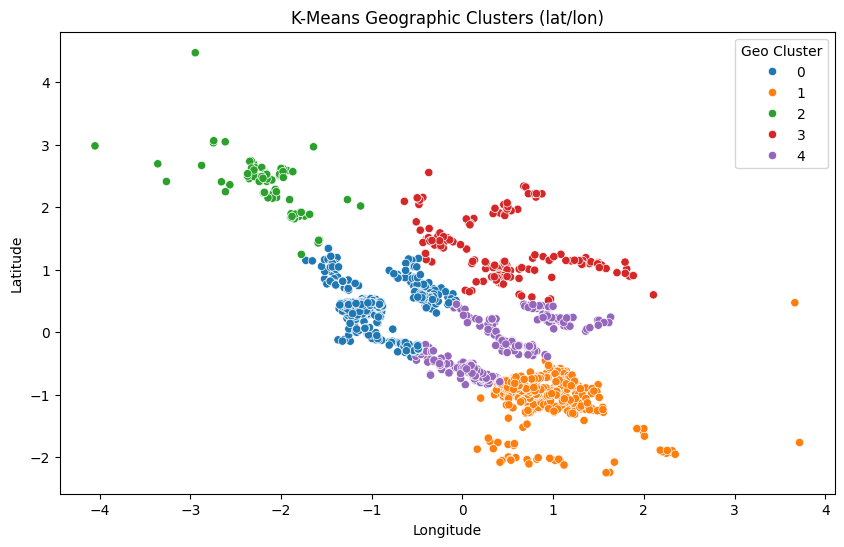

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot latitude vs longitude colored by geographic cluster
plt.figure(figsize=(10,6))
sns.scatterplot(data=scaled_df,
                x='lon',
                y='lat',
                hue='geo_cluster',
                palette='tab10')

plt.title("K-Means Geographic Clusters (lat/lon)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title='Geo Cluster')
plt.show()

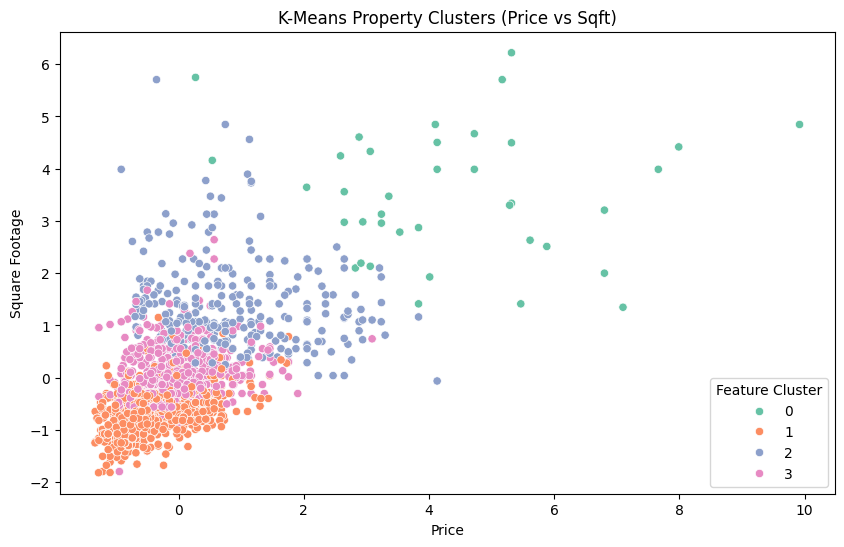

In [ ]:
# Plot price vs square footage colored by feature cluster
plt.figure(figsize=(10,6))
sns.scatterplot(data=scaled_df,
                x='price',
                y='sqft',
                hue='homefeature_cluster',
                palette='Set2')

plt.title("K-Means Property Clusters (Price vs Sqft)")
plt.xlabel("Price")
plt.ylabel("Square Footage")
plt.legend(title='Feature Cluster')
plt.show()

### 🔧 **Try It Yourself - Part 5**

In past assignments you’ve created scatterplots where the size of each point depended on how large each value was. And you’ve created scatterplots where the color of each point was assigned many or few colors.



5.1. Re-plot the above `price` vs `sqft` scatterplot with the following: Add `beds` as the **point size** and add `baths` as the **point style**

5.2. Group by `homefeature_cluster` and calculate:
  - Average `price`
  - Average `sqft`
  - Average `beds`  


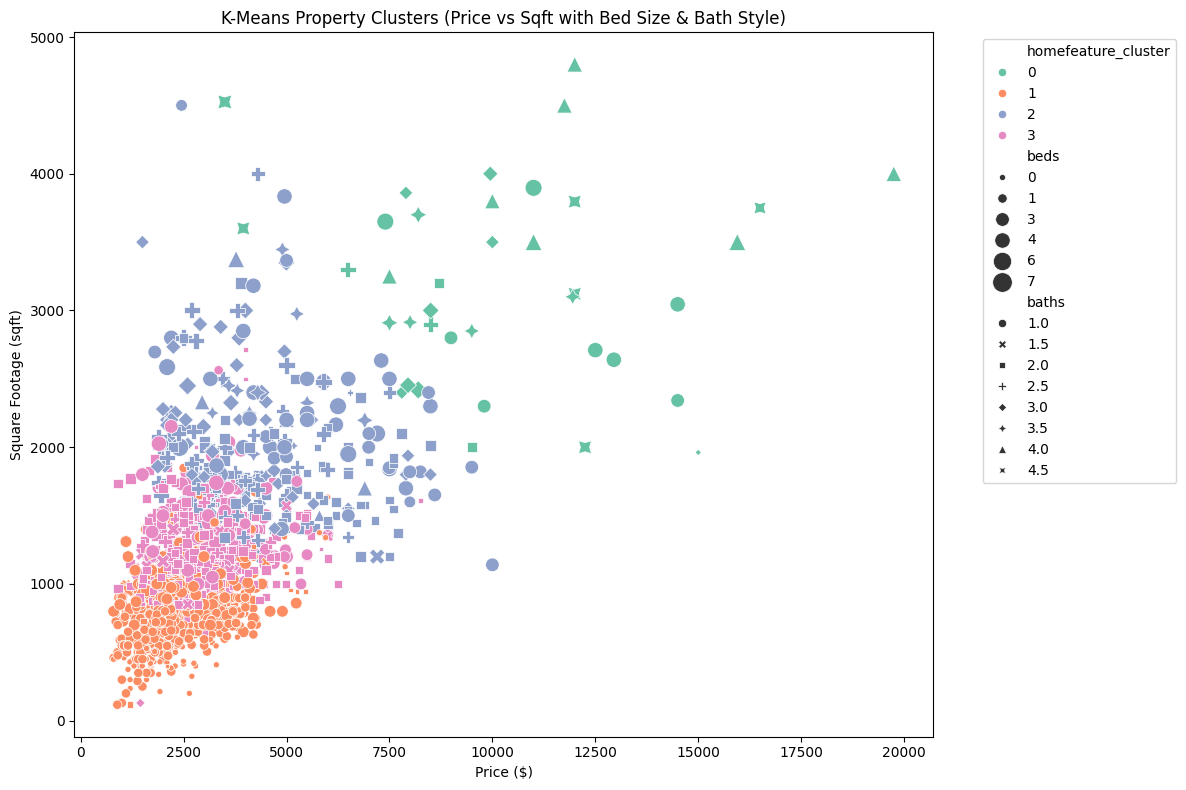

Average metrics grouped by homefeature_cluster:


,price,sqft,beds
homefeature_cluster,,,
0,10353.552632,3210.421053,4.263158
1,2374.169247,804.315789,1.251806
2,4409.967213,1961.000000,3.498361
3,2984.035714,1241.553571,2.391369


In [ ]:
# 🔧 5.1. Add code here to replot the scatterplot
plt.figure(figsize=(12, 8))
# We map 'homefeature_cluster' back to original df if not already done, or use scaled_df.
# Let's map scaled_df features and clusters together for consistent plotting
plot_df = df.copy()
plot_df['homefeature_cluster'] = scaled_df['homefeature_cluster']

sns.scatterplot(
    data=plot_df,
    x='price',
    y='sqft',
    hue='homefeature_cluster',
    size='beds',
    style='baths',
    sizes=(20, 200),
    palette='Set2'
)

plt.title("K-Means Property Clusters (Price vs Sqft with Bed Size & Bath Style)")
plt.xlabel("Price ($)")
plt.ylabel("Square Footage (sqft)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# 🔧 5.2. Group by homefeature_cluster and calculate average price, sqft, and beds
print("Average metrics grouped by homefeature_cluster:")
summary_stats = plot_df.groupby('homefeature_cluster')[['price', 'sqft', 'beds']].mean()
display(summary_stats)

## **Part 6: Evaluate the Fit for your Clusters**

We’ll now use three methods to evaluate the fit:
- **WCSS**: Within-cluster sums of squares
- **Silhouette score**
- **Davies-bouldin index**

### Why This Matters:
Clusters are difficult to visualize when they are based on more than 3 variables.  A statistical score will evaluate the fit across all of the variables.

### Things to think about:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering



### 🔧 **Try It Yourself – Part 6**

Calculate the three scores for your **feature-based** cluster model by using the following methods:

6.1. WCSS

6.2. Silhouette score

6.3. Davies-bouldin index

Typically, we would compare these scores for different k to help us pick the optimal number of clusters.

In [ ]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

# 🔧 6.1. Add code here - WCSS
wcss = kmeans_home.inertia_
print(f"WCSS: {wcss}")

# 🔧 6.2. Add code here - Silhouette score
silhouette_avg = silhouette_score(X_home, scaled_df['homefeature_cluster'])
print(f"Silhouette Score: {silhouette_avg}")

# 🔧 6.3. Add code here - Davies-bouldin index
db_index = davies_bouldin_score(X_home, scaled_df['homefeature_cluster'])
print(f"Davies-Bouldin Index: {db_index}")

WCSS: 3084.0910931937105
Silhouette Score: 0.34137171564974733
Davies-Bouldin Index: 1.2373318849835946


## 🔧 **Part 7: Reflection (100 words or less per question)**

7.1. Which method—manual binning or KMeans clustering—gave you more useful insights? Why?

7.2. How might missing data or outliers affect your segmentation results?


🔧 7.1. Add comment here

I think KMeans clustering gave me more useful insights. It can group houses based on different features, like price, size, and bedrooms. From the graphs, I can see that some groups have higher prices and larger houses. Manual binning is easier to understand, but KMeans shows more differences between houses.


🔧 7.2. Add comment here

Missing data can make the results less accurate because some houses may not have enough information. Outliers, like houses with very high prices, can also affect the clusters. They may change how houses are grouped. This is why cleaning the data is important before clustering.

## Export Your Notebook to Submit in Canvas
- Use the instructions from Lab 1

In [ ]:
!jupyter nbconvert --to html "lab_09_Gong Linlin.ipynb"

[NbConvertApp] Converting notebook lab_09_Gong Linlin.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 4 image(s).
[NbConvertApp] Writing 863773 bytes to lab_09_Gong Linlin.html
